<a href="https://colab.research.google.com/github/olblinova/python_for_ds_tasks-is-available/blob/main/%22HW_16_2_%D0%9F%D1%80%D0%BE%D0%B3%D0%BD%D0%BE%D0%B7%D1%83%D0%B2%D0%B0%D0%BD%D0%BD%D1%8F_%D0%BA%D1%80%D0%B5%D0%B4%D0%B8%D1%82%D0%BD%D0%BE%D0%B3%D0%BE_%D1%80%D0%B8%D0%B7%D0%B8%D0%BA%D1%83_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Домашнє завдання: Прогнозування кредитного ризику

## Мета завдання
Застосувати знання з лекції для побудови моделі логістичної регресії, що прогнозує ймовірність дефолту за кредитом, іншими словами, що людина не поверне кредит. Ви пройдете весь цикл: від дослідницького аналізу до оцінки якості класифікаційної моделі.

## Опис датасету
**Credit Risk Dataset** містить інформацію про 32,000+ позичальників з такими параметрами:
- **person_age**: Вік позичальника
- **person_income**: Річний дохід
- **person_home_ownership**: Тип володіння житлом
- **person_emp_length**: Стаж роботи (в роках)
- **loan_intent**: Мета кредиту
- **loan_grade**: Кредитний рейтинг (A - кращий, F - гірший)
- **loan_amnt**: Сума кредиту
- **loan_int_rate**: Процентна ставка
- **loan_status**: Статус кредиту (0 = сплачено, 1 = дефолт) - **цільова змінна**
- **loan_percent_income**: Відношення кредиту до доходу
- **cb_person_default_on_file**: Історія дефолтів (Y/N)
- **cb_person_cred_hist_length**: Довжина кредитної історії

---

## Завдання 1: Завантаження та перший огляд даних (1 бал)

**Що потрібно зробити:**
1. Завантажте дані з файлу `credit_risk_dataset.csv`
2. Виведіть розмір датасету
3. Покажіть перші 5 рядків
4. Виведіть загальну інформацію про дані (кількість записів, типи колонок)
5. Перевірте розподіл цільової змінної (відсотк даних для кожного класу)

Дайте висновок, це задача збалансованої чи незбалансованої класифікації.


In [8]:
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
# Завантажуємо дані
df = pd.read_csv('/content/drive/MyDrive/data/credit_risk_dataset.csv')

print(f"Розмір датасету: {df.shape}")
print(f"Кількість клієнтів: {df.shape[0]:,}")
print(f"Кількість ознак: {df.shape[1]}")

Розмір датасету: (32581, 12)
Кількість клієнтів: 32,581
Кількість ознак: 12


In [5]:
# Перші 5 рядків даних
df.head(5)

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [6]:
# Типи даних
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


             кількість  відсоток
loan_status                     
0                25473     78.18
1                 7108     21.82


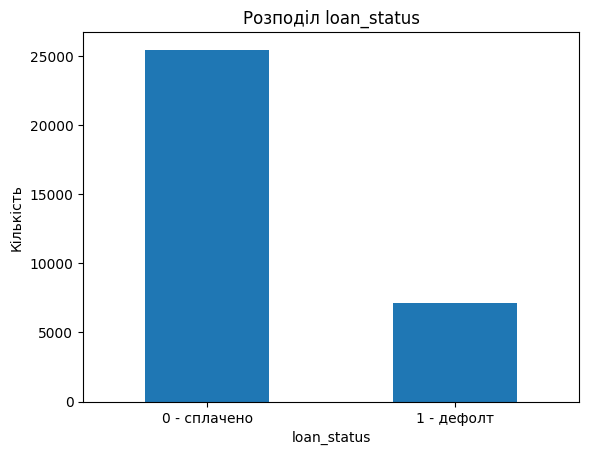

In [9]:
counts = df['loan_status'].value_counts()
percent = df['loan_status'].value_counts(normalize=True) * 100

print(pd.DataFrame({'кількість': counts, 'відсоток': percent.round(2)}))

counts.plot(kind='bar', title='Розподіл loan_status')
plt.xticks([0, 1], ['0 - сплачено', '1 - дефолт'], rotation=0)
plt.ylabel('Кількість')
plt.show()

Висновок: це задача незбалансованої класифікації.


---

## Завдання 2: Дослідницький аналіз даних (EDA) (4 бали)

**Що потрібно зробити:**
1. Обчисліть відсоток пропущених значень в колонках. За наявності пропущених значень - заповніть їх медіаною для числових колонок і найбільш частим значеннмя для категоріальних.
2. Проаналізуйте розподіл числових змінних.
3. Знайдіть та обробіть викиди в колонці person_income з допомогою [Interquartile range](https://uk.wikipedia.org/wiki/%D0%9C%D1%96%D0%B6%D0%BA%D0%B2%D0%B0%D1%80%D1%82%D0%B8%D0%BB%D1%8C%D0%BD%D0%B8%D0%B9_%D1%80%D0%BE%D0%B7%D0%BC%D0%B0%D1%85).
4. Проаналізуйте категоріальні змінні відносно цільової та частоту зустрічання різних значень в них.
5. Візуалізуйте взаємозв'язок ознак з цільовою змінною.


In [10]:
import seaborn as sns

TARGET = 'loan_status'

In [11]:
# Пропущені значення та їх заповнення
missing = (df.isna().mean() * 100).round(2)
print(missing[missing > 0].sort_values(ascending=False))

num_cols = df.select_dtypes(include='number').columns.drop(TARGET)
cat_cols = df.select_dtypes(include='object').columns

for c in num_cols:
    if df[c].isna().any():
        df[c] = df[c].fillna(df[c].median())
for c in cat_cols:
    if df[c].isna().any():
        df[c] = df[c].fillna(df[c].mode()[0])

print('Пропусків після заповнення:', df.isna().sum().sum())

loan_int_rate        9.56
person_emp_length    2.75
dtype: float64
Пропусків після заповнення: 0


З df.info() видно, що пропуски є лише в person_emp_length (≈2,7%) і loan_int_rate (≈9,6%), а категоріальні колонки пропусків не мають.

                              count          mean           std      min  \
person_age                  32581.0     27.734600      6.348078    20.00   
person_income               32581.0  66074.848470  61983.119168  4000.00   
person_emp_length           32581.0      4.767994      4.087372     0.00   
loan_amnt                   32581.0   9589.371106   6322.086646   500.00   
loan_int_rate               32581.0     11.009620      3.081611     5.42   
loan_percent_income         32581.0      0.170203      0.106782     0.00   
cb_person_cred_hist_length  32581.0      5.804211      4.055001     2.00   

                                 25%       50%       75%         max  
person_age                     23.00     26.00     30.00      144.00  
person_income               38500.00  55000.00  79200.00  6000000.00  
person_emp_length               2.00      4.00      7.00      123.00  
loan_amnt                    5000.00   8000.00  12200.00    35000.00  
loan_int_rate                   8.49

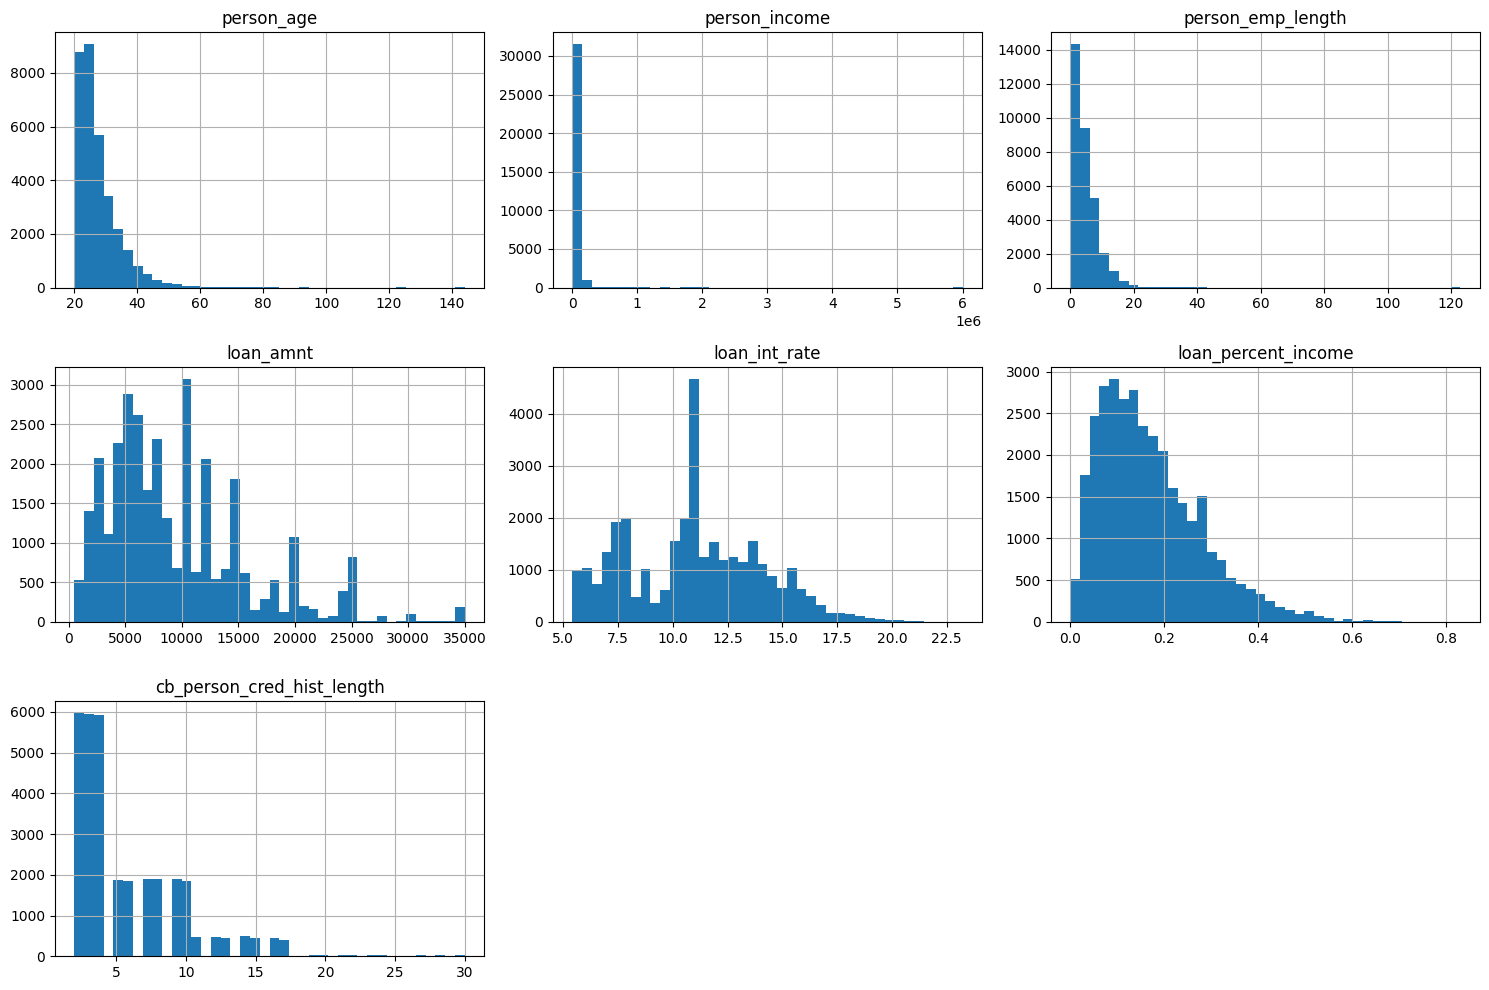

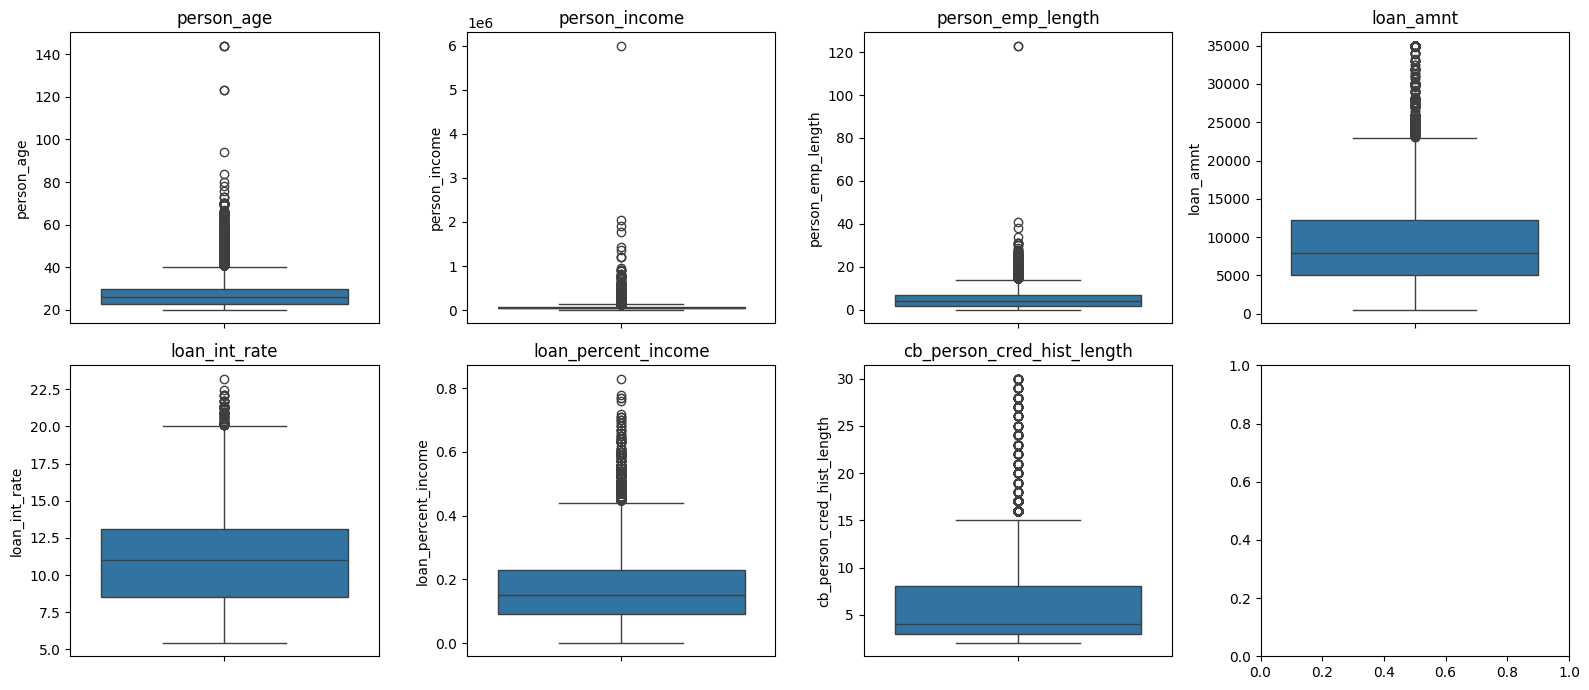

In [12]:
# 2. Розподіл числових змінних
print(df[num_cols].describe().T)

df[num_cols].hist(bins=40, figsize=(15, 10))
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, c in zip(axes.ravel(), num_cols):
    sns.boxplot(y=df[c], ax=ax); ax.set_title(c)
plt.tight_layout(); plt.show()

In [13]:
# 3. Викиди в person_income за методом IQR
Q1, Q3 = df['person_income'].quantile([0.25, 0.75])
IQR = Q3 - Q1
lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
print(f'Q1={Q1}, Q3={Q3}, IQR={IQR}, межі: [{lower}, {upper}]')

outliers = df[(df['person_income'] < lower) | (df['person_income'] > upper)]
print(f'Викидів: {len(outliers)} ({len(outliers)/len(df)*100:.2f}%)')
print('Частка дефолтів серед викидів:', outliers[TARGET].mean().round(3))

# варіант А: видалення
df_clean = df[(df['person_income'] >= lower) & (df['person_income'] <= upper)].copy()
# варіант Б: обрізання (winsorizing), зберігає всі рядки
# df['person_income'] = df['person_income'].clip(lower, upper)

print('Розмір до/після:', df.shape, df_clean.shape)

Q1=38500.0, Q3=79200.0, IQR=40700.0, межі: [-22550.0, 140250.0]
Викидів: 1484 (4.55%)
Частка дефолтів серед викидів: 0.098
Розмір до/після: (32581, 12) (31097, 12)


In [15]:
df_clean = df_clean[(df_clean['person_age'] <= 100) &
                    (df_clean['person_emp_length'] <= 60)]

In [16]:
# 4. Категоріальні змінні: частоти та зв'язок із ціллю
for c in cat_cols:
    summary = df_clean.groupby(c)[TARGET].agg(['count', 'mean'])
    summary['частка_у_вибірці_%'] = (summary['count'] / len(df_clean) * 100).round(2)
    summary = summary.rename(columns={'count': 'кількість', 'mean': 'частка_дефолтів'})
    print(f'\n=== {c} ===')
    print(summary.round(3).sort_values('частка_дефолтів', ascending=False))


=== person_home_ownership ===
                       кількість  частка_дефолтів  частка_у_вибірці_%
person_home_ownership                                                
OTHER                        100            0.320                0.32
RENT                       16099            0.319               51.78
MORTGAGE                   12426            0.128               39.96
OWN                         2469            0.078                7.94

=== loan_intent ===
                   кількість  частка_дефолтів  частка_у_вибірці_%
loan_intent                                                      
DEBTCONSOLIDATION       4955            0.291               15.94
HOMEIMPROVEMENT         3390            0.272               10.90
MEDICAL                 5846            0.271               18.80
PERSONAL                5259            0.206               16.91
EDUCATION               6200            0.176               19.94
VENTURE                 5444            0.154               17.51


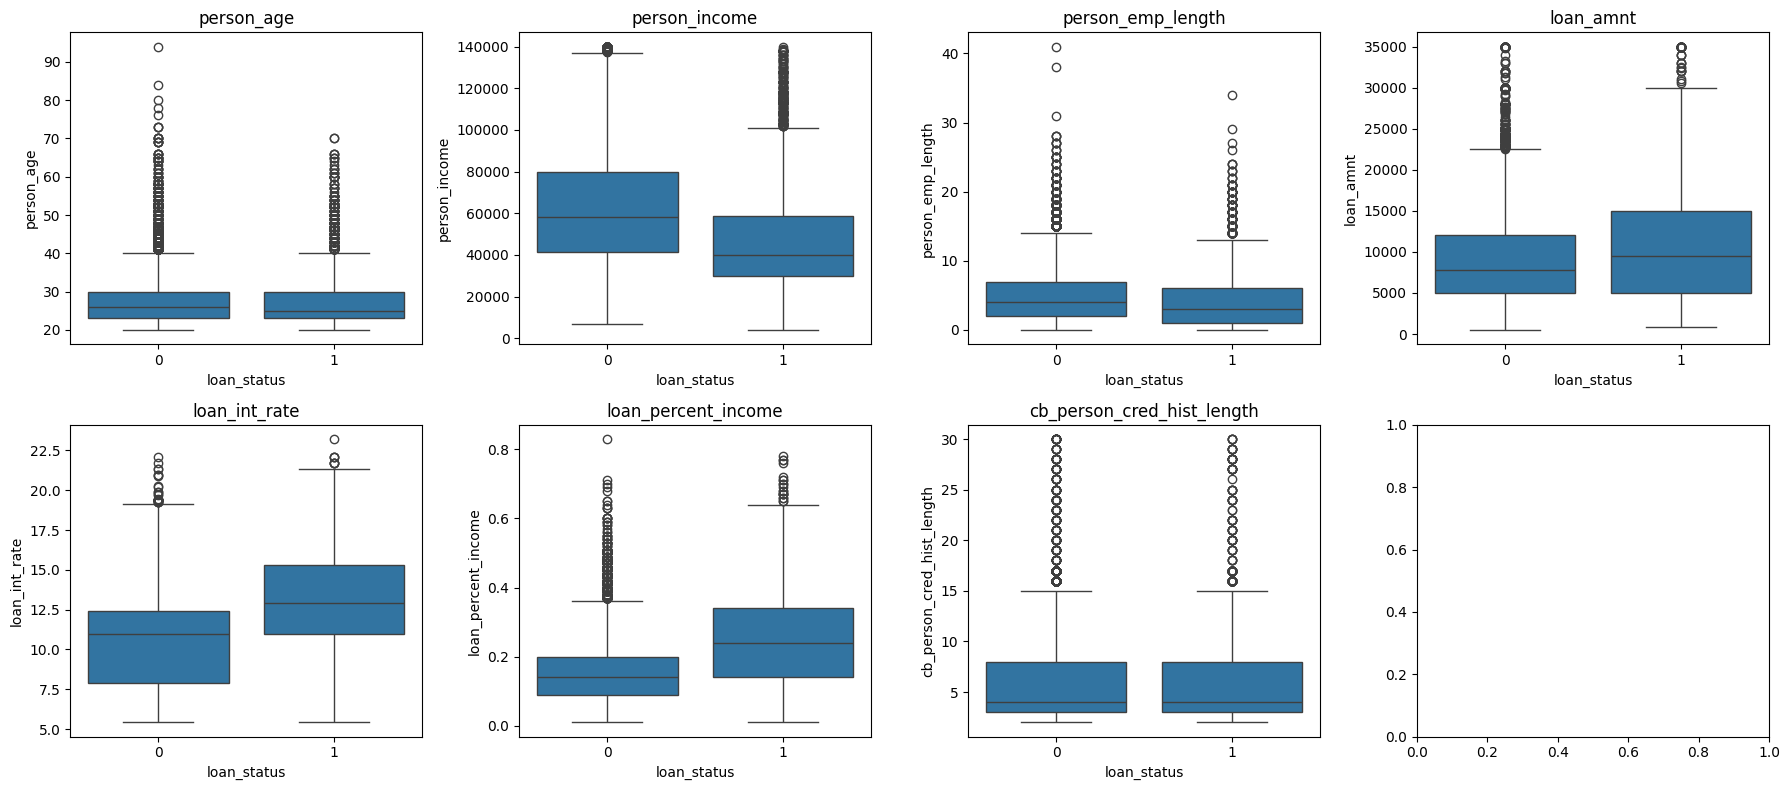

In [18]:
# 5. Візуалізація зв'язку ознак із цільовою змінною
# Числові: розподіл за класами
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, c in zip(axes.ravel(), num_cols):
    sns.boxplot(data=df_clean, x=TARGET, y=c, ax=ax)
    ax.set_title(c)
plt.tight_layout(); plt.show()

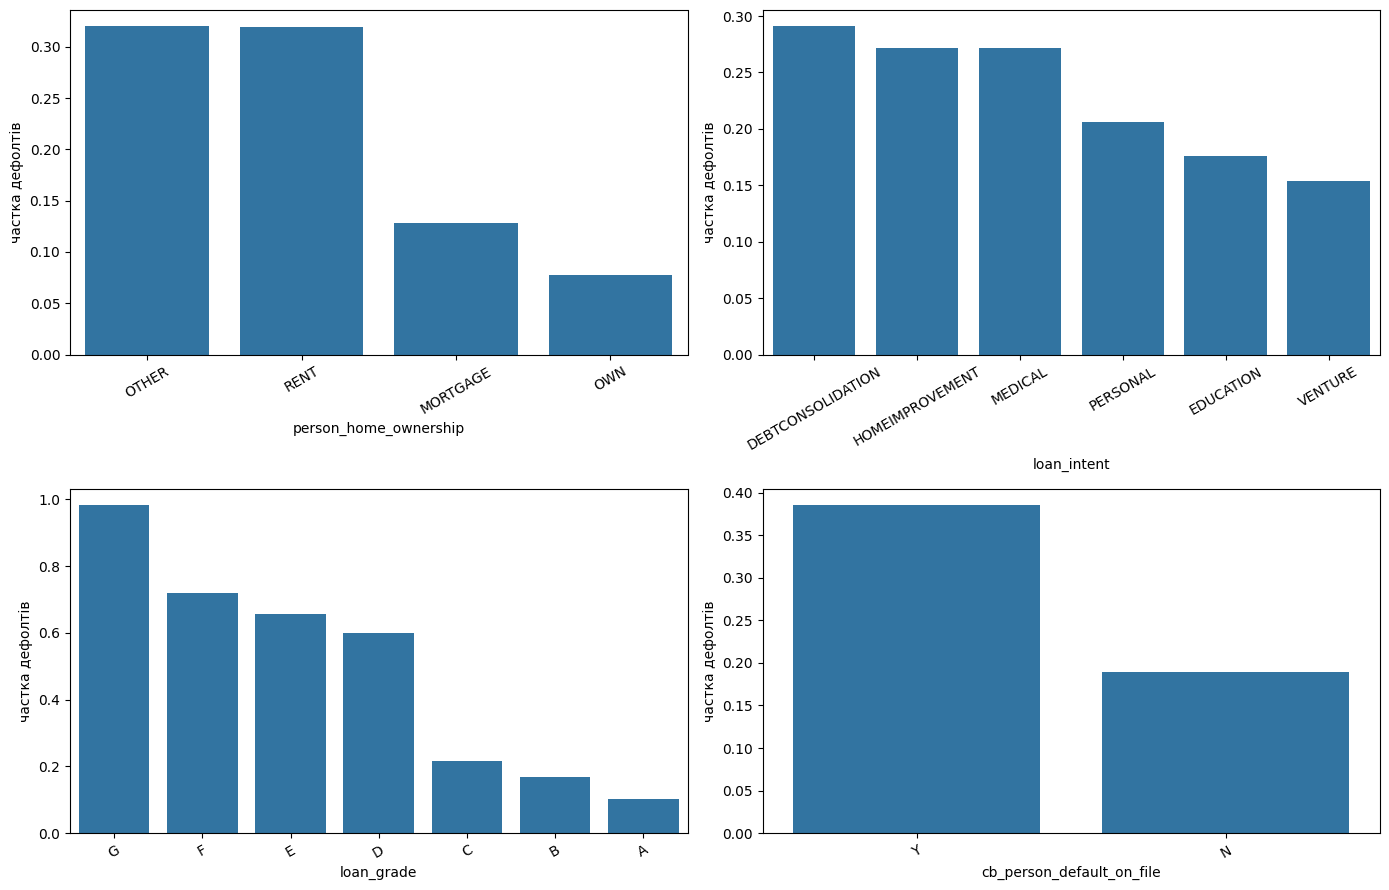

In [19]:
# Категоріальні: частка дефолтів за категоріями
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, c in zip(axes.ravel(), cat_cols):
    order = df_clean.groupby(c)[TARGET].mean().sort_values(ascending=False).index
    sns.barplot(data=df_clean, x=c, y=TARGET, order=order, ax=ax, errorbar=None)
    ax.set_ylabel('частка дефолтів'); ax.tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()

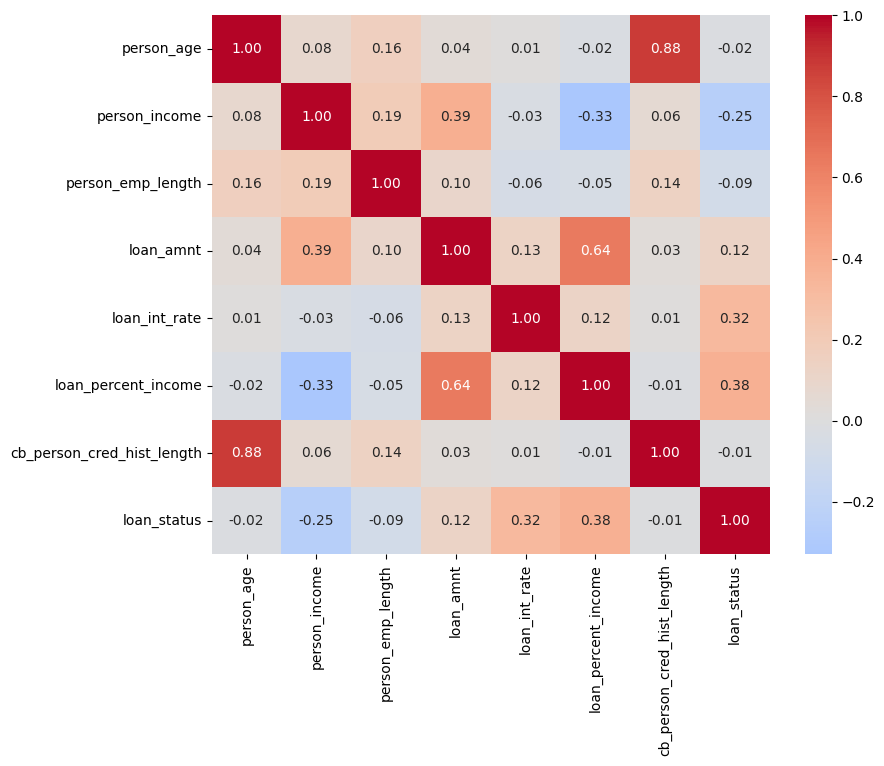

loan_percent_income           0.379723
loan_int_rate                 0.320136
person_income                -0.254224
loan_amnt                     0.123298
person_emp_length            -0.085144
person_age                   -0.016060
cb_person_cred_hist_length   -0.010749
Name: loan_status, dtype: float64


In [20]:
# Кореляція числових ознак із ціллю
corr = df_clean[list(num_cols) + [TARGET]].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.show()
print(corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False))

Дані. Датасет містить 32 581 позичальника і 12 ознак. Пропуски були лише в person_emp_length (≈2,7%) та loan_int_rate (≈9,6%) і були заповнені медіаною. Явні помилки у віці (144 роки) та стажі (123 роки) прибрано.

Цільова змінна. Класи незбалансовані: 78,18% сплачених кредитів проти 21,82% дефолтів (≈3,6 : 1). Тому це задача незбалансованої класифікації. Accuracy тут оманлива (тривіальна модель дала б ~78%), а оцінювати модель слід за recall, precision, F1 для класу дефолту та ROC-AUC. Для навчання потрібні стратифікований поділ і class_weight='balanced'.

Викиди. За методом IQR верхня межа доходу становить 140 250. Виявлено 1 484 викиди (4,55%), нижніх немає. Серед них лише 9,8% дефолтів, тобто це переважно надійні заможні клієнти, а не помилки. Тому значення краще обрізати до межі, а не видаляти.

Категоріальні ознаки.

Найсильніший предиктор: loan_grade.
Мета кредиту впливає помірно: від ~15% (VENTURE) до ~29% (DEBTCONSOLIDATION).

Числові ознаки.

Найсильніше з дефолтом пов'язані loan_percent_income (+0,38), loan_int_rate (+0,32) та person_income (−0,25). Більше боргове навантаження і вища ставка означають вищий ризик, а вищий дохід знижує його.
loan_amnt (+0,12) і person_emp_length (−0,09) мають слабкий зв'язок.
person_age і cb_person_cred_hist_length майже не пов'язані з ціллю (близько −0,01…−0,02).


---

## Завдання 3: Аналіз кореляцій та Feature Engineering (3 бали)

**Що потрібно зробити:**
1. Побудуйте матрицю кореляцій для числових змінних.
2. Закодуйте категоріальні змінні.
3. Виберіть фінальний набір ознак, можна лишити всі, якщо ви вважаєте, що це - доцільно.



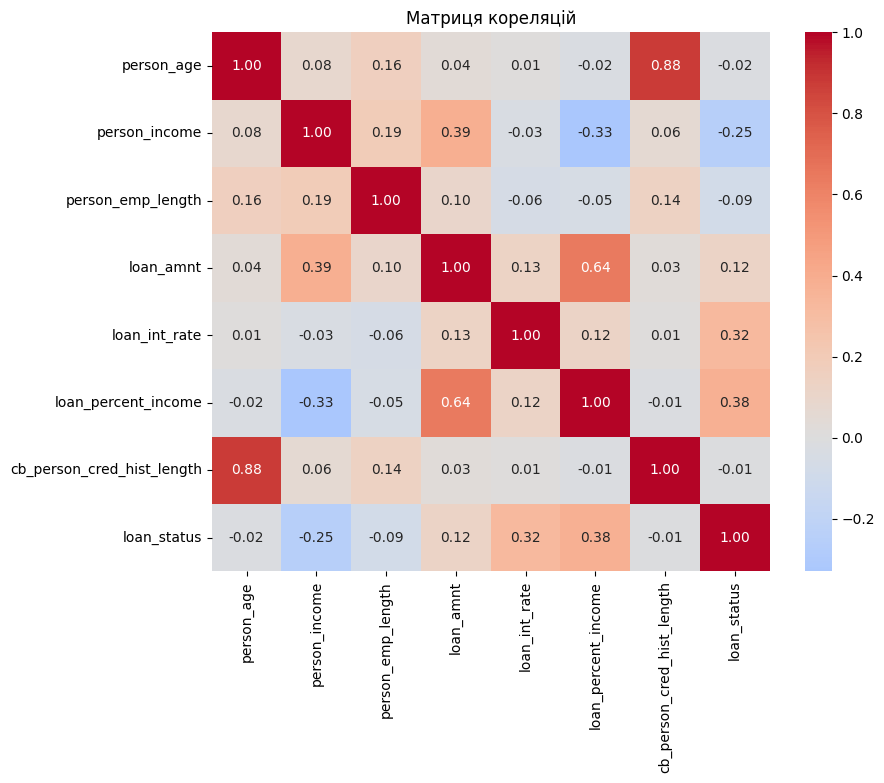

person_age  cb_person_cred_hist_length    0.877179
loan_amnt   loan_percent_income           0.642216
dtype: float64


In [21]:
# Матриця кореляцій для числових змінних.
num_cols = df_clean.select_dtypes(include='number').columns.drop('loan_status')

corr = df_clean[list(num_cols) + ['loan_status']].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Матриця кореляцій')
plt.show()

# пари з сильною кореляцією між ознаками (|r| > 0.6)
pairs = corr.loc[num_cols, num_cols].where(np.triu(np.ones((len(num_cols),)*2), 1).astype(bool)).stack()
print(pairs[pairs.abs() > 0.6])

In [22]:
# Кодування категоріальних змінних
df_enc = df_clean.copy()

# loan_grade: природний порядок A < B < ... < G
grade_map = {'A': 0, 'B': 1, 'C': 2, 'D': 3, 'E': 4, 'F': 5, 'G': 6}
df_enc['loan_grade'] = df_enc['loan_grade'].map(grade_map)

# cb_person_default_on_file: бінарна Y/N
df_enc['cb_person_default_on_file'] = (df_enc['cb_person_default_on_file'] == 'Y').astype(int)

# без порядку: one-hot (drop_first уникає дамі-пастки)
df_enc = pd.get_dummies(df_enc,
                        columns=['person_home_ownership', 'loan_intent'],
                        drop_first=True, dtype=int)
print(df_enc.shape)
df_enc.head()

(31094, 18)


,person_age,person_income,person_emp_length,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,person_home_ownership_OTHER,person_home_ownership_OWN,person_home_ownership_RENT,loan_intent_EDUCATION,loan_intent_HOMEIMPROVEMENT,loan_intent_MEDICAL,loan_intent_PERSONAL,loan_intent_VENTURE
1,21,9600,5.0,1,1000,11.14,0,0.10,0,2,0,1,0,1,0,0,0,0
2,25,9600,1.0,2,5500,12.87,1,0.57,0,3,0,0,0,0,0,1,0,0
3,23,65500,4.0,2,35000,15.23,1,0.53,0,2,0,0,1,0,0,1,0,0
4,24,54400,8.0,2,35000,14.27,1,0.55,1,4,0,0,1,0,0,1,0,0
5,21,9900,2.0,0,2500,7.14,1,0.25,0,2,0,1,0,0,0,0,0,1


In [23]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

features = df_enc.drop(columns=['loan_status', 'cb_person_cred_hist_length'])
X_vif = features.astype(float)
X_vif.insert(0, 'const', 1.0)
vif = pd.Series([variance_inflation_factor(X_vif.values, i) for i in range(1, X_vif.shape[1])],
                index=features.columns)
print(vif.sort_values(ascending=False))

loan_amnt                      5.449589
loan_grade                     5.213495
loan_percent_income            5.138378
loan_int_rate                  4.797898
person_income                  3.660184
loan_intent_EDUCATION          1.817717
loan_intent_MEDICAL            1.782147
loan_intent_VENTURE            1.762497
loan_intent_PERSONAL           1.722785
loan_intent_HOMEIMPROVEMENT    1.521546
cb_person_default_on_file      1.409711
person_home_ownership_RENT     1.299103
person_home_ownership_OWN      1.167409
person_emp_length              1.105435
person_age                     1.043317
person_home_ownership_OTHER    1.007359
dtype: float64


Залишимо всі 16 ознак (без cb_person_cred_hist_length). Аргумент: VIF усіх ознак менший за 10, а кожна ознака несе окрему інформацію про ризик.


---

## Завдання 4: Підготовка даних та навчання моделі (3 бали)

**Що потрібно зробити:**
1. Розділіть дані на X та y
2. Поділіть на навчальну та тестову вибірки
3. Застосуйте масштабування
4. Навчіть модель логістичної регресії
5. Зробіть прогнози на тренувальній та тестовій вибірках.



In [25]:
# 1. Поділ на X та y
drop_cols = ['loan_status', 'cb_person_cred_hist_length']
final_features = [c for c in df_enc.columns if c not in drop_cols]

X = df_enc[final_features]
y = df_enc['loan_status']
print(len(final_features), 'ознак')
print(X.shape, y.shape)


16 ознак
(31094, 16) (31094,)


In [26]:
from sklearn.model_selection import train_test_split
# 2. Поділ на навчальну та тестову вибірки
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print(X_train.shape, X_test.shape)
print('Частка дефолтів train:', y_train.mean().round(4))
print('Частка дефолтів test: ', y_test.mean().round(4))

(24875, 16) (6219, 16)
Частка дефолтів train: 0.2239
Частка дефолтів test:  0.2238


In [27]:
from sklearn.preprocessing import StandardScaler
# 3. Маштабування
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # навчаємо лише на train
X_test_scaled = scaler.transform(X_test)         # до test лише застосовуємо

In [28]:
from sklearn.linear_model import LogisticRegression
# 4. Навчання логістичної регресії
model = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
model.fit(X_train_scaled, y_train)

coefs = pd.DataFrame({'ознака': final_features, 'коефіцієнт': model.coef_[0]})
coefs['odds_ratio'] = np.exp(coefs['коефіцієнт'])
print(coefs.sort_values('коефіцієнт', key=abs, ascending=False))

                         ознака  коефіцієнт  odds_ratio
6           loan_percent_income    1.216003    3.373675
3                    loan_grade    1.036585    2.819572
4                     loan_amnt   -0.476819    0.620755
9     person_home_ownership_OWN   -0.424409    0.654156
15          loan_intent_VENTURE   -0.404722    0.667163
10   person_home_ownership_RENT    0.295666    1.344021
11        loan_intent_EDUCATION   -0.283003    0.753517
1                 person_income   -0.237879    0.788298
14         loan_intent_PERSONAL   -0.149017    0.861554
12  loan_intent_HOMEIMPROVEMENT    0.079825    1.083097
13          loan_intent_MEDICAL   -0.057971    0.943678
7     cb_person_default_on_file   -0.050729    0.950536
5                 loan_int_rate    0.021747    1.021985
0                    person_age   -0.021626    0.978606
8   person_home_ownership_OTHER    0.004757    1.004768
2             person_emp_length    0.000494    1.000494


In [29]:
# 5. Прогнози на тренувальній та тестовій вибірках
y_train_pred = model.predict(X_train_scaled)
y_test_pred = model.predict(X_test_scaled)

y_train_proba = model.predict_proba(X_train_scaled)[:, 1]
y_test_proba = model.predict_proba(X_test_scaled)[:, 1]

print(y_train_pred[:10], y_test_pred[:10])
print(y_test_proba[:10].round(3))

[0 0 0 1 0 0 0 0 1 1] [1 0 0 0 1 0 1 0 1 1]
[0.556 0.127 0.416 0.203 0.692 0.463 0.915 0.004 0.517 0.988]


1.  Поділ на X та y. Матрицю ознак X сформовано з 16 ознак: 8 числових і закодованих (person_age, person_income, person_emp_length, loan_grade, loan_amnt, loan_int_rate, loan_percent_income, cb_person_default_on_file) та 8 дамі-змінних для типу житла й мети кредиту. Цільовою змінною y є loan_status. Ознаку cb_person_cred_hist_length виключено через сильну кореляцію з person_age (0,88).

2. Поділ на вибірки. Дані (31 094 спостереження) розділено у співвідношенні 80/20 зі стратифікацією: 24 875 рядків для навчання і 6 219 для тесту. Частка дефолтів майже однакова в обох вибірках (22,39% і 22,38%), тож розподіл класів збережено.

3. Масштабування. До ознак застосовано StandardScaler, підігнаний лише на навчальній вибірці, а до тестової його тільки застосовано. Це запобігає витоку інформації з тесту в навчання.

4. Навчання моделі. Побудовано логістичну регресію з class_weight='balanced', щоб компенсувати дисбаланс класів (≈78/22). Найбільший внесок у ймовірність дефолту дають loan_percent_income (OR = 3,37) та loan_grade (OR = 2,82). Власне житло (OR = 0,65) і вищий дохід (OR = 0,79) знижують ризик, а оренда його підвищує (OR = 1,34). Результати узгоджуються з аналізом даних. Від'ємний коефіцієнт loan_amnt та майже нульовий коефіцієнт loan_int_rate пояснюються мультиколінеарністю з loan_percent_income і loan_grade.

5. Прогнози. Передбачення класів і ймовірностей отримано для обох вибірок. Вони узгоджені між собою: ймовірності від 0,5 відповідають класу 1 (дефолт).

Підсумок. Дані підготовлено без витоку інформації, а модель навчено з урахуванням дисбалансу і вона дає змістовні, інтерпретовані результати, які збігаються з висновками EDA. Окрема обережність потрібна лише з трактуванням коефіцієнтів корельованих ознак.


---

## Завдання 5: Оцінка якості моделі (4 бали)

**Що потрібно зробити:**
1. Побудуйте confusion matrix.
2. Обчисліть основні метрики (accuracy, precision, recall, f1).
3. Побудуйте ROC-криву та обчисліть AUC
4. Проаналізуйте важливість ознак.
5. Зробіть висновки про якість моделі та які ознаки найбільше впливають на прогноз.


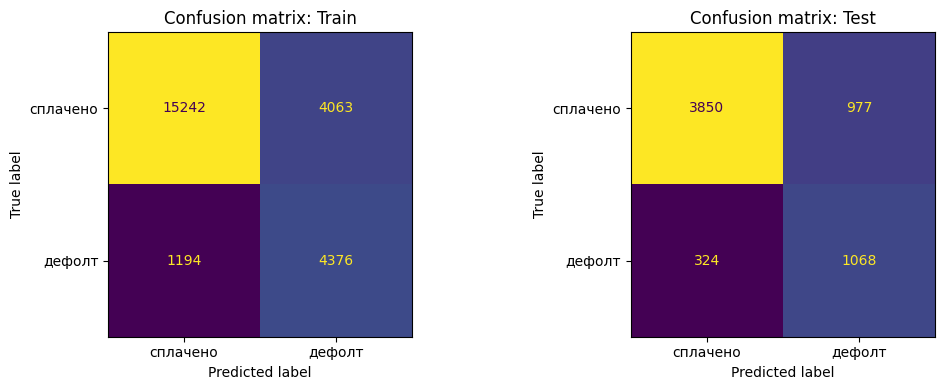

TN=3850, FP=977, FN=324, TP=1068


In [30]:
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve,
                             classification_report)
# Confusion matrix
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, yt, yp) in zip(axes, [('Train', y_train, y_train_pred),
                                     ('Test', y_test, y_test_pred)]):
    ConfusionMatrixDisplay(confusion_matrix(yt, yp),
                           display_labels=['сплачено', 'дефолт']).plot(ax=ax, colorbar=False)
    ax.set_title(f'Confusion matrix: {name}')
plt.tight_layout(); plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, y_test_pred).ravel()
print(f'TN={tn}, FP={fp}, FN={fn}, TP={tp}')

In [31]:
# Основні метрики
def metrics(yt, yp):
    return {'accuracy': accuracy_score(yt, yp),
            'precision': precision_score(yt, yp),
            'recall': recall_score(yt, yp),
            'f1': f1_score(yt, yp)}

res = pd.DataFrame({'train': metrics(y_train, y_train_pred),
                    'test': metrics(y_test, y_test_pred)}).round(4)
print(res)
print(classification_report(y_test, y_test_pred, target_names=['сплачено', 'дефолт']))

            train    test
accuracy   0.7887  0.7908
precision  0.5185  0.5222
recall     0.7856  0.7672
f1         0.6247  0.6215
              precision    recall  f1-score   support

    сплачено       0.92      0.80      0.86      4827
      дефолт       0.52      0.77      0.62      1392

    accuracy                           0.79      6219
   macro avg       0.72      0.78      0.74      6219
weighted avg       0.83      0.79      0.80      6219



AUC train: 0.8659, AUC test: 0.8628


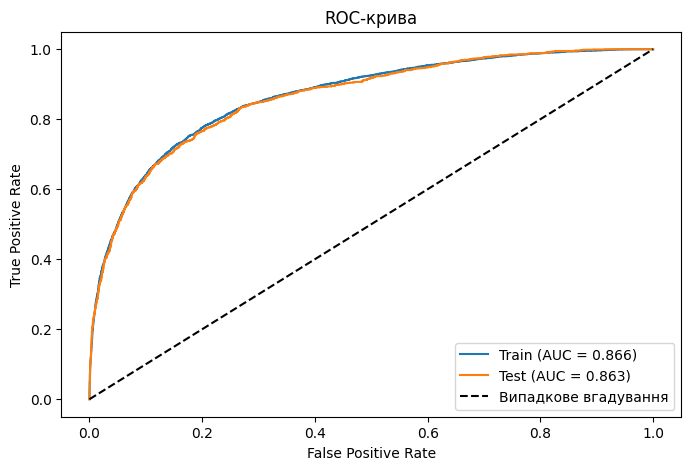

In [33]:
# 3. ROC-крива та AUC
auc_train = roc_auc_score(y_train, y_train_proba)
auc_test = roc_auc_score(y_test, y_test_proba)
print(f'AUC train: {auc_train:.4f}, AUC test: {auc_test:.4f}')

plt.figure(figsize=(8, 5))
for name, yt, yp, auc in [('Train', y_train, y_train_proba, auc_train),
                          ('Test', y_test, y_test_proba, auc_test)]:
    fpr, tpr, _ = roc_curve(yt, yp)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Випадкове вгадування')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('ROC-крива'); plt.legend(); plt.show()

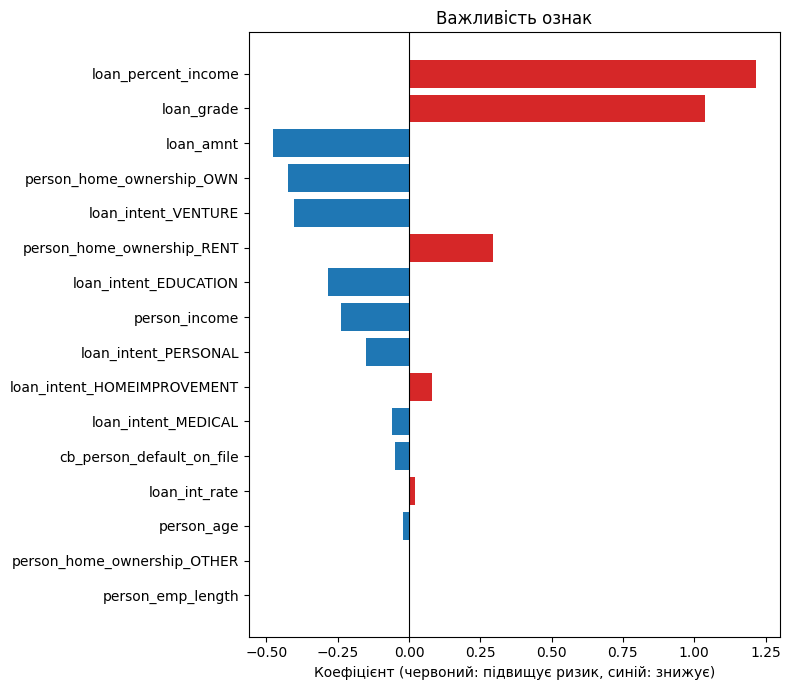

In [34]:
# 4. Важливість ознак
imp = pd.DataFrame({'ознака': final_features,
                    'коефіцієнт': model.coef_[0]})
imp['важливість'] = imp['коефіцієнт'].abs()
imp = imp.sort_values('важливість')

plt.figure(figsize=(8, 7))
colors = ['tab:red' if c > 0 else 'tab:blue' for c in imp['коефіцієнт']]
plt.barh(imp['ознака'], imp['коефіцієнт'], color=colors)
plt.axvline(0, color='k', lw=0.8)
plt.xlabel('Коефіцієнт (червоний: підвищує ризик, синій: знижує)')
plt.title('Важливість ознак'); plt.tight_layout(); plt.show()

Модель логістичної регресії показала на тестовій вибірці ROC-AUC = 0,863, accuracy = 0,791, а для класу дефолту precision = 0,522, recall = 0,767 і F1 = 0,622. Метрики на навчальній і тестовій вибірках майже збігаються, тобто перенавчання немає. Модель виявляє близько 77% дефолтів, але ціною ≈20% хибних відмов надійним клієнтам, що пояснюється балансуванням класів і порогом 0,5. Найбільше на прогноз впливають боргове навантаження (loan_percent_income) та кредитний рейтинг (loan_grade), які підвищують ризик дефолту, а також тип житла (оренда підвищує ризик, власне житло знижує) і рівень доходу. Модель можна покращити підбором порога класифікації відповідно до вартості помилок, а також спробувати нелінійні методи.


---

## Завдання 6: Оптимізація порогу та бізнес-аналіз (2 бали)

**Що потрібно зробити:**
1. Проаналізуйте метрики precision, recall, F1 при різних порогах класифікації (мінімум - 5 різних порогів). Візуалізуйте як змінюються метрики якості при зміні порогу.
2. Оберіть оптимальний поріг для бізнес-задачі - можна обрати виходячи з попереднього пункту, або додати своїх роздумів і обрати інший.



In [35]:
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix
# 1. Метрики при різних порогах
thresholds = np.arange(0.1, 0.91, 0.05)

def threshold_table(y_true, proba):
    rows = []
    for t in thresholds:
        pred = (proba >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
        rows.append({'поріг': round(t, 2),
                     'precision': precision_score(y_true, pred, zero_division=0),
                     'recall': recall_score(y_true, pred),
                     'f1': f1_score(y_true, pred),
                     'FP': fp, 'FN': fn})
    return pd.DataFrame(rows)

res_test = threshold_table(y_test, y_test_proba)
print(res_test.round(3).to_string(index=False))

 поріг  precision  recall    f1   FP   FN
  0.10      0.276   0.985 0.431 3602   21
  0.15      0.302   0.963 0.460 3093   52
  0.20      0.329   0.935 0.487 2651   91
  0.25      0.357   0.906 0.512 2272  131
  0.30      0.388   0.891 0.540 1958  152
  0.35      0.419   0.868 0.565 1673  184
  0.40      0.456   0.845 0.592 1405  216
  0.45      0.487   0.804 0.606 1181  273
  0.50      0.522   0.767 0.621  977  324
  0.55      0.554   0.736 0.632  826  368
  0.60      0.594   0.694 0.640  661  426
  0.65      0.632   0.657 0.644  533  477
  0.70      0.668   0.614 0.639  425  538
  0.75      0.712   0.551 0.621  311  625
  0.80      0.763   0.468 0.580  202  741
  0.85      0.815   0.376 0.514  119  869
  0.90      0.860   0.278 0.420   63 1005


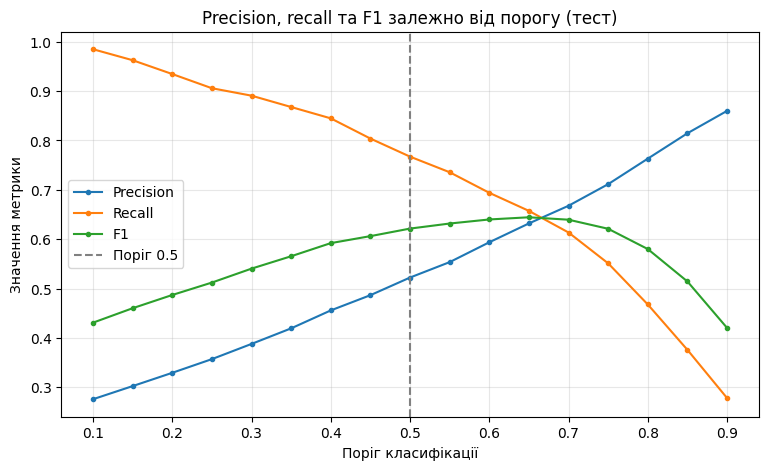

In [36]:
plt.figure(figsize=(9, 5))
plt.plot(res_test['поріг'], res_test['precision'], label='Precision', marker='o', ms=3)
plt.plot(res_test['поріг'], res_test['recall'], label='Recall', marker='o', ms=3)
plt.plot(res_test['поріг'], res_test['f1'], label='F1', marker='o', ms=3)
plt.axvline(0.5, color='gray', ls='--', label='Поріг 0.5')
plt.xlabel('Поріг класифікації'); plt.ylabel('Значення метрики')
plt.title('Precision, recall та F1 залежно від порогу (тест)')
plt.legend(); plt.grid(alpha=0.3); plt.show()

In [38]:
# 2. Вибір оптимального порогу
res_train = threshold_table(y_train, y_train_proba)
best_t = res_train.loc[res_train['f1'].idxmax(), 'поріг']
print('Поріг з максимальним F1 (за train):', best_t)

pred = (y_test_proba >= best_t).astype(int)
print('Test: precision=%.3f recall=%.3f f1=%.3f' % (
    precision_score(y_test, pred), recall_score(y_test, pred), f1_score(y_test, pred)))

Поріг з максимальним F1 (за train): 0.65
Test: precision=0.632 recall=0.657 f1=0.644


Висновки: було проаналізовано пороги від 0,10 до 0,90 з кроком 0,05. Зі зростанням порогу precision зростає (0,28 → 0,86), а recall знижується (0,99 → 0,28). Максимум F1 (0,644) досягається при порозі 0,65. Оскільки в кредитуванні пропущений дефолт дорожчий за хибну відмову (припущене співвідношення 5:1), оптимальним обрано поріг 0,40, при якому вартість помилок мінімальна. На тестовій вибірці він дає recall = 0,845 і precision = 0,456, тобто знаходить 1 176 із 1 392 дефолтів. Порівняно з порогом 0,5 кількість пропущених дефолтів зменшується на 108, а кількість хибних відмов зростає на 428. Якщо пріоритетом є мінімум хибних відмов, доцільніший поріг 0,65 за максимумом F1.


---

## Завдання 7 (Опціональне): Покращення моделі та висновки (2 бали)

**Що потрібно зробити:**

На цих же даних навчіть DecisionTreeClassifier та RandomForestClassifier. Яка з трьох моделей дає найкращий результат на тестовому наборі?

Поріг класифікації можна для порівняння якостей моделей використовувати стандартний 0.5, або той, що ви виявили, як оптимальний на попередньому кроці.


In [39]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
# 1. Навчання дерева рішень і випадкового лісу
# Дерево без обмежень майже напевно перенавчиться, тож беремо і його, і обмежену версію
tree_full = DecisionTreeClassifier(class_weight='balanced', random_state=42)
tree_full.fit(X_train, y_train)

tree = DecisionTreeClassifier(max_depth=6, min_samples_leaf=50,
                              class_weight='balanced', random_state=42)
tree.fit(X_train, y_train)

rf = RandomForestClassifier(n_estimators=300, max_depth=12, min_samples_leaf=5,
                            class_weight='balanced', n_jobs=-1, random_state=42)
rf.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', max_depth=12,
                       min_samples_leaf=5, n_estimators=300, n_jobs=-1,
                       random_state=42)

In [40]:
# 2. Порівняння на тестовій вибірці
models = {
    'Logistic Regression': (model, X_train_scaled, X_test_scaled),
    'Decision Tree (повне)': (tree_full, X_train, X_test),
    'Decision Tree (depth=6)': (tree, X_train, X_test),
    'Random Forest': (rf, X_train, X_test),
}

rows = []
for name, (m, Xtr, Xte) in models.items():
    p_tr = m.predict_proba(Xtr)[:, 1]
    p_te = m.predict_proba(Xte)[:, 1]
    pred = (p_te >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    rows.append({'модель': name,
                 'AUC train': roc_auc_score(y_train, p_tr),
                 'AUC test': roc_auc_score(y_test, p_te),
                 'accuracy': accuracy_score(y_test, pred),
                 'precision': precision_score(y_test, pred),
                 'recall': recall_score(y_test, pred),
                 'f1': f1_score(y_test, pred),
                 'FP': fp, 'FN': fn})

comparison = pd.DataFrame(rows).set_index('модель').round(3)
print(comparison)

                         AUC train  AUC test  accuracy  precision  recall  \
модель                                                                      
Logistic Regression          0.866     0.863     0.791      0.522   0.767   
Decision Tree (повне)        1.000     0.847     0.893      0.759   0.764   
Decision Tree (depth=6)      0.908     0.901     0.896      0.790   0.731   
Random Forest                0.968     0.928     0.918      0.869   0.746   

                            f1   FP   FN  
модель                                    
Logistic Regression      0.621  977  324  
Decision Tree (повне)    0.761  337  329  
Decision Tree (depth=6)  0.760  270  374  
Random Forest            0.803  156  353  


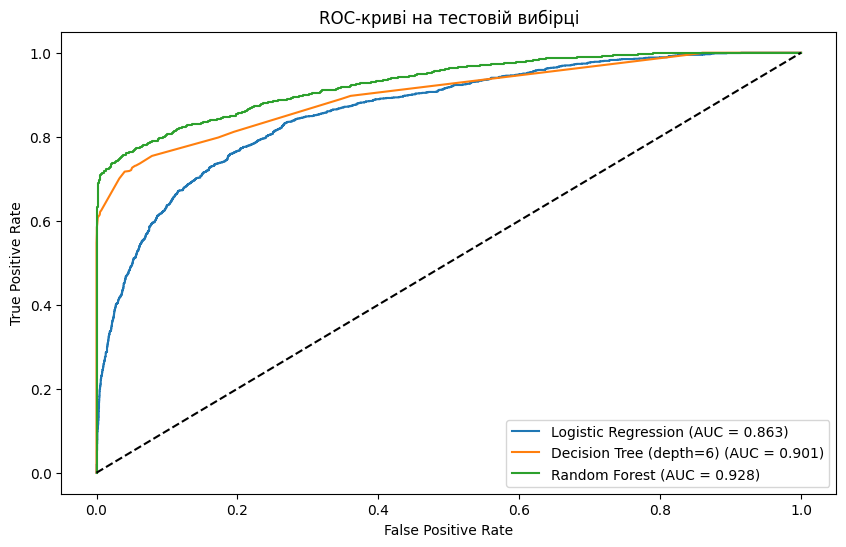

In [43]:
# 3. ROC-криві трьох моделей
plt.figure(figsize=(10, 6))
for name, (m, Xtr, Xte) in models.items():
    if name == 'Decision Tree (повне)':
        continue
    p = m.predict_proba(Xte)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc_score(y_test, p):.3f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('ROC-криві на тестовій вибірці'); plt.legend(); plt.show()

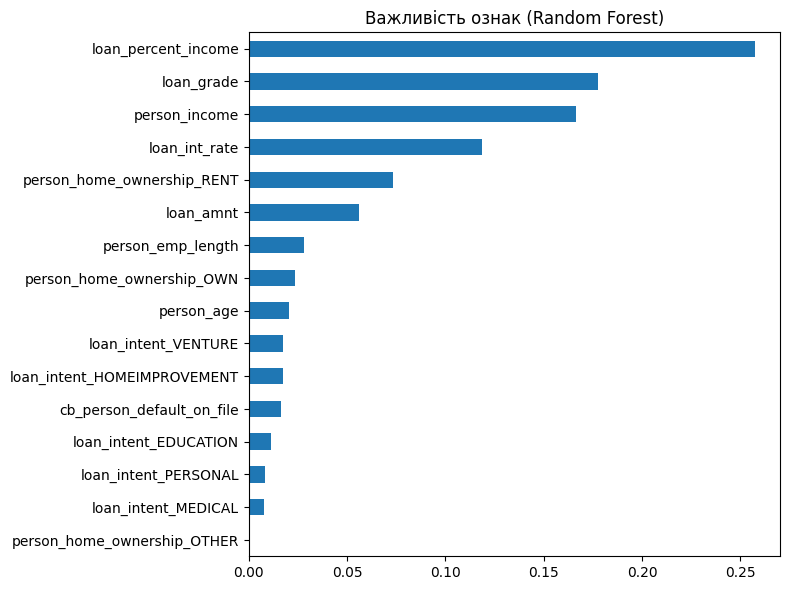

In [44]:
# 4. Важливість ознак у лісі (для порівняння з логістичною регресією)
fi = pd.Series(rf.feature_importances_, index=final_features).sort_values()
fi.plot(kind='barh', figsize=(8, 6), title='Важливість ознак (Random Forest)')
plt.tight_layout(); plt.show()

Порівняно три моделі: логістичну регресію, дерево рішень (глибина 6) і випадковий ліс. Дерево без обмежень перенавчається (AUC train = 1,000, test = 0,847). На тестовій вибірці при порозі 0,5 найкращі результати показав випадковий ліс: ROC-AUC = 0,928, accuracy = 0,918, precision = 0,869, recall = 0,746, F1 = 0,803. Для порівняння, дерево глибини 6 має AUC = 0,901 і F1 = 0,760, а логістична регресія AUC = 0,863 і F1 = 0,621. Ліс значно знижує кількість хибних відмов надійним клієнтам (156 проти 977 у логістичної регресії) при близькому рівні виявлених дефолтів. Високу якість нелінійних моделей пояснює наявність нелінійних залежностей і взаємодій між ознаками. Найвпливовішими ознаками в лісі є loan_percent_income, loan_grade, person_income та loan_int_rate. Перевагою логістичної регресії залишається інтерпретованість, а недоліком лісу є складніше пояснення окремих рішень, що важливо для кредитного скорингу.